In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/ishaans23/segmentation-training-artifact/training_history.csv
/kaggle/input/datasets/ishaans23/segmentation-training-artifact/training_summary.json
/kaggle/input/datasets/ishaans23/segmentation-training-artifact/unet_best.pth
/kaggle/input/datasets/ishaans23/final-classifier-artifact/head_training_history.csv
/kaggle/input/datasets/ishaans23/final-classifier-artifact/layer4_training_history.csv
/kaggle/input/datasets/ishaans23/final-classifier-artifact/model_metadata.json
/kaggle/input/datasets/ishaans23/final-classifier-artifact/resnet50_layer4_best.pth
/kaggle/input/datasets/ishaans23/final-classifier-artifact/training_summary.json
/kaggle/input/datasets/ishaans23/cbis-ddsm-training/cache_info.json
/kaggle/input/datasets/ishaans23/cbis-ddsm-training/excluded_mass_cases.csv
/kaggle/input/datasets/ishaans23/cbis-ddsm-training/image_metadata.csv
/kaggle/input/datasets/ishaans23/cbis-ddsm-training/shared_mass_calc_audit.csv
/kaggle/input/datasets/ishaans23/cbis-dds

In [3]:
from pathlib import Path
import json
import shutil
import zipfile

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from torchvision.models import (
    resnet50,
    ResNet50_Weights,
)

from tqdm.auto import tqdm

from IPython.display import (
    display as notebook_display,
)

In [4]:
SEED = 42

TARGET_HEIGHT = 1024
TARGET_WIDTH = 640

BATCH_SIZE = 2
NUM_WORKERS = 0

OUTPUT_DIR = Path(
    "/kaggle/working/segmentation_evaluation"
)

FIGURE_DIR = (
    OUTPUT_DIR / "figures"
)

PREDICTION_DIR = (
    OUTPUT_DIR / "predicted_masks"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

PREDICTION_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print("Output:", OUTPUT_DIR)

Output: /kaggle/working/segmentation_evaluation


In [5]:
KAGGLE_INPUT_ROOT = Path(
    "/kaggle/input"
)

dataset_candidates = []

for cache_info_path in KAGGLE_INPUT_ROOT.rglob(
    "cache_info.json"
):

    candidate_root = (
        cache_info_path.parent
    )

    required_paths = [
        candidate_root / "npy",
        candidate_root / "masks",
        candidate_root / "splits",
    ]

    if all(
        path.exists()
        for path in required_paths
    ):

        dataset_candidates.append(
            candidate_root
        )

assert len(dataset_candidates) > 0, (
    "Could not locate the model-ready "
    "CBIS-DDSM dataset."
)

dataset_candidates = sorted(
    dataset_candidates,
    key=lambda path: len(str(path)),
)

PROJECT_ROOT = (
    dataset_candidates[0]
)

print("Dataset:")
print(PROJECT_ROOT)

Dataset:
/kaggle/input/datasets/ishaans23/cbis-ddsm-training


In [6]:
# ============================================================
# LOCATE RESNET50-U-NET TRAINING ARTIFACT
# ============================================================

KAGGLE_INPUT_ROOT = Path(
    "/kaggle/input"
)


def find_resnet50_unet_summary(
    search_root,
):

    candidates = []

    for summary_path in search_root.rglob(
        "training_summary.json"
    ):

        try:

            with open(
                summary_path,
                "r",
            ) as f:

                summary = json.load(f)

            if (
                summary.get("architecture")
                == "ResNet50UNet"
                and summary.get(
                    "selected_checkpoint"
                )
                ==
                "resnet50_unet_layer4_best.pth"
            ):

                candidates.append(
                    (
                        summary_path,
                        summary,
                    )
                )

        except Exception:
            continue

    return candidates


# ------------------------------------------------------------
# First try normal Kaggle input directories
# ------------------------------------------------------------

summary_candidates = (
    find_resnet50_unet_summary(
        KAGGLE_INPUT_ROOT
    )
)


# ------------------------------------------------------------
# If Kaggle left the artifact zipped, extract it
# ------------------------------------------------------------

if len(summary_candidates) == 0:

    zip_candidates = list(
        KAGGLE_INPUT_ROOT.rglob(
            "resnet50_unet_training_artifact.zip"
        )
    )

    assert len(zip_candidates) > 0, (
        "Could not find the "
        "ResNet50-U-Net training artifact."
    )

    zip_file = zip_candidates[0]

    EXTRACT_DIR = Path(
        "/kaggle/working/"
        "resnet50_unet_artifact_extracted"
    )

    if EXTRACT_DIR.exists():
        shutil.rmtree(
            EXTRACT_DIR
        )

    EXTRACT_DIR.mkdir(
        parents=True,
        exist_ok=True,
    )

    with zipfile.ZipFile(
        zip_file,
        "r",
    ) as archive:

        archive.extractall(
            EXTRACT_DIR
        )

    summary_candidates = (
        find_resnet50_unet_summary(
            EXTRACT_DIR
        )
    )


# ------------------------------------------------------------
# Verify artifact
# ------------------------------------------------------------

assert len(summary_candidates) > 0, (
    "Valid ResNet50-U-Net "
    "training_summary.json not found."
)


TRAINING_SUMMARY_PATH, training_summary = (
    summary_candidates[0]
)

SEGMENTATION_ARTIFACT_ROOT = (
    TRAINING_SUMMARY_PATH.parent
)

CHECKPOINT_PATH = (
    SEGMENTATION_ARTIFACT_ROOT
    / training_summary[
        "selected_checkpoint"
    ]
)


assert CHECKPOINT_PATH.exists(), (
    f"Checkpoint missing: "
    f"{CHECKPOINT_PATH}"
)


print(
    "Segmentation artifact:"
)

print(
    SEGMENTATION_ARTIFACT_ROOT
)


print(
    "\nSelected checkpoint:"
)

print(
    CHECKPOINT_PATH
)


print(
    "\nExpected validation soft Dice:",
    training_summary[
        "selected_validation_soft_dice"
    ],
)

Segmentation artifact:
/kaggle/input/datasets/ishaans23/resnet50-unet-training-artifact

Selected checkpoint:
/kaggle/input/datasets/ishaans23/resnet50-unet-training-artifact/resnet50_unet_layer4_best.pth

Expected validation soft Dice: 0.3570995714772103


In [7]:
SPLITS_DIR = (
    PROJECT_ROOT / "splits"
)

val_df = pd.read_csv(
    SPLITS_DIR / "val.csv"
)

print(
    "Validation samples:",
    len(val_df)
)

print(
    "\nValidation abnormality distribution:"
)

print(
    val_df[
        "abnormality_type"
    ].value_counts()
)

Validation samples: 408

Validation abnormality distribution:
abnormality_type
calcification         215
mass                  185
mass+calcification      8
Name: count, dtype: int64


In [8]:
class RAMEvaluationDataset(Dataset):

    def __init__(
        self,
        images,
        masks,
        image_keys,
    ):

        self.images = images
        self.masks = masks
        self.image_keys = image_keys


    def __len__(
        self,
    ):

        return len(
            self.image_keys
        )


    def __getitem__(
        self,
        idx,
    ):

        return (
            self.images[idx],
            self.masks[idx],
            self.image_keys[idx],
        )

In [9]:
def load_segmentation_split_into_ram(
    dataframe,
    root_dir,
    split_name,
):

    num_samples = len(
        dataframe
    )


    images = np.empty(
        (
            num_samples,
            TARGET_HEIGHT,
            TARGET_WIDTH,
        ),
        dtype=np.uint16,
    )


    masks = np.empty(
        (
            num_samples,
            TARGET_HEIGHT,
            TARGET_WIDTH,
        ),
        dtype=np.uint8,
    )


    image_keys = (
        dataframe[
            "image_key"
        ].tolist()
    )


    for i, row in enumerate(
        tqdm(
            dataframe.itertuples(
                index=False
            ),
            total=num_samples,
            desc=(
                f"Loading {split_name} "
                "into RAM"
            ),
        )
    ):

        image = np.load(
            root_dir
            / row.npy_path
        )


        mask = cv2.imread(
            str(
                root_dir
                / row.mask_path
            ),
            cv2.IMREAD_GRAYSCALE,
        )


        if image.shape != (
            TARGET_HEIGHT,
            TARGET_WIDTH,
        ):

            raise ValueError(
                f"{row.image_key}: "
                f"unexpected image shape "
                f"{image.shape}"
            )


        if mask is None:

            raise ValueError(
                f"{row.image_key}: "
                "mask could not be loaded"
            )


        if mask.shape != (
            TARGET_HEIGHT,
            TARGET_WIDTH,
        ):

            raise ValueError(
                f"{row.image_key}: "
                f"unexpected mask shape "
                f"{mask.shape}"
            )


        images[i] = image

        masks[i] = (
            mask > 0
        ).astype(
            np.uint8
        )


    images = torch.from_numpy(
        images
    )

    masks = torch.from_numpy(
        masks
    )


    print(
        f"\n{split_name}: "
        f"{num_samples} samples loaded"
    )

    print(
        "Images:",
        images.shape,
        images.dtype,
    )

    print(
        "Masks:",
        masks.shape,
        masks.dtype,
    )


    return RAMEvaluationDataset(
        images=images,
        masks=masks,
        image_keys=image_keys,
    )

In [10]:
val_dataset = (
    load_segmentation_split_into_ram(
        dataframe=val_df,
        root_dir=PROJECT_ROOT,
        split_name="Validation",
    )
)


val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)


print(
    "\nValidation batches:",
    len(val_loader)
)

Loading Validation into RAM:   0%|          | 0/408 [00:00<?, ?it/s]


Validation: 408 samples loaded
Images: torch.Size([408, 1024, 640]) torch.uint16
Masks: torch.Size([408, 1024, 640]) torch.uint8

Validation batches: 204


In [11]:
# ============================================================
# DEVICE
# ============================================================

device = torch.device(
    "cuda:0"
    if torch.cuda.is_available()
    else "cpu"
)

print(
    "Device:",
    device
)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )


# ============================================================
# NORMALIZATION FROM RESNET50 WEIGHT DEFINITION
# ============================================================

resnet_weights = (
    ResNet50_Weights.DEFAULT
)

weight_transforms = (
    resnet_weights.transforms()
)


IMAGENET_MEAN = torch.tensor(
    weight_transforms.mean,
    dtype=torch.float32,
    device=device,
).view(
    1,
    3,
    1,
    1,
)


IMAGENET_STD = torch.tensor(
    weight_transforms.std,
    dtype=torch.float32,
    device=device,
).view(
    1,
    3,
    1,
    1,
)


print(
    "Normalization mean:",
    weight_transforms.mean
)

print(
    "Normalization std:",
    weight_transforms.std
)


# ============================================================
# PREPARE BATCH
# ============================================================

def prepare_segmentation_batch(
    images,
    masks,
):

    images = images.to(
        device,
        non_blocking=True,
    )

    masks = masks.to(
        device,
        non_blocking=True,
    )


    # uint16 -> float [0, 1]
    images = (
        images.float()
        / 65535.0
    )


    # grayscale -> RGB
    images = (
        images
        .unsqueeze(1)
        .repeat(
            1,
            3,
            1,
            1,
        )
    )


    # Same normalization used during
    # classifier/segmentation training.
    images = (
        images
        - IMAGENET_MEAN
    ) / IMAGENET_STD


    masks = (
        masks.float()
        .unsqueeze(1)
    )


    return images, masks

Device: cuda:0
GPU: Tesla T4
Normalization mean: [0.485, 0.456, 0.406]
Normalization std: [0.229, 0.224, 0.225]


In [12]:
class DecoderBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        skip_channels,
        out_channels,
    ):

        super().__init__()


        self.up = nn.ConvTranspose2d(
            in_channels,
            out_channels,
            kernel_size=2,
            stride=2,
        )


        self.conv = nn.Sequential(

            nn.Conv2d(
                out_channels
                + skip_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False,
            ),

            nn.GroupNorm(
                8,
                out_channels,
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False,
            ),

            nn.GroupNorm(
                8,
                out_channels,
            ),

            nn.ReLU(
                inplace=True
            ),
        )


    def forward(
        self,
        x,
        skip,
    ):

        x = self.up(
            x
        )

        x = torch.cat(
            [
                x,
                skip,
            ],
            dim=1,
        )

        return self.conv(
            x
        )

In [13]:
class ResNet50UNet(nn.Module):

    def __init__(
        self,
        backbone,
    ):

        super().__init__()


        # ====================================================
        # RESNET-50 ENCODER
        # ====================================================

        self.conv1 = (
            backbone.conv1
        )

        self.bn1 = (
            backbone.bn1
        )

        self.relu = (
            backbone.relu
        )

        self.maxpool = (
            backbone.maxpool
        )

        self.layer1 = (
            backbone.layer1
        )

        self.layer2 = (
            backbone.layer2
        )

        self.layer3 = (
            backbone.layer3
        )

        self.layer4 = (
            backbone.layer4
        )


        # ====================================================
        # SEGMENTATION DECODER
        # ====================================================

        self.up4 = DecoderBlock(
            2048,
            1024,
            512,
        )

        self.up3 = DecoderBlock(
            512,
            512,
            256,
        )

        self.up2 = DecoderBlock(
            256,
            256,
            128,
        )

        self.up1 = DecoderBlock(
            128,
            64,
            64,
        )


        self.final_up = nn.Sequential(

            nn.ConvTranspose2d(
                64,
                32,
                kernel_size=2,
                stride=2,
            ),

            nn.GroupNorm(
                8,
                32,
            ),

            nn.ReLU(
                inplace=True
            ),
        )


        self.output = nn.Conv2d(
            32,
            1,
            kernel_size=1,
        )


    def forward(
        self,
        x,
    ):

        # ----------------------------------------------------
        # Encoder
        # ----------------------------------------------------

        e0 = self.relu(
            self.bn1(
                self.conv1(x)
            )
        )

        x = self.maxpool(
            e0
        )


        e1 = self.layer1(
            x
        )

        e2 = self.layer2(
            e1
        )

        e3 = self.layer3(
            e2
        )

        e4 = self.layer4(
            e3
        )


        # ----------------------------------------------------
        # Decoder
        # ----------------------------------------------------

        d4 = self.up4(
            e4,
            e3,
        )

        d3 = self.up3(
            d4,
            e2,
        )

        d2 = self.up2(
            d3,
            e1,
        )

        d1 = self.up1(
            d2,
            e0,
        )


        x = self.final_up(
            d1
        )


        return self.output(
            x
        )

In [14]:
# ============================================================
# BUILD RESNET50-U-NET
# ============================================================

backbone = resnet50(
    weights=None
)


model = ResNet50UNet(
    backbone=backbone
)


total_parameters = sum(
    parameter.numel()
    for parameter
    in model.parameters()
)


print(
    "Model:",
    "ResNet50UNet"
)

print(
    "Parameters:",
    f"{total_parameters:,}"
)

Model: ResNet50UNet
Parameters: 40,900,481


In [15]:
# ============================================================
# LOAD FINAL STAGE-B CHECKPOINT
# ============================================================

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False,
)


model.load_state_dict(
    checkpoint[
        "model_state_dict"
    ]
)


model = model.to(
    device
)

model.eval()


# ============================================================
# VERIFY CHECKPOINT
# ============================================================

checkpoint_soft_dice = float(
    checkpoint[
        "val_metrics"
    ]["soft_dice"]
)


expected_soft_dice = float(
    training_summary[
        "selected_validation_soft_dice"
    ]
)


print(
    "Checkpoint stage:",
    checkpoint.get(
        "stage"
    )
)

print(
    "Checkpoint epoch:",
    checkpoint["epoch"]
)

print(
    "Validation soft Dice:",
    checkpoint_soft_dice
)

print(
    "Validation hard Dice:",
    checkpoint[
        "val_metrics"
    ]["hard_dice"]
)

print(
    "Validation IoU:",
    checkpoint[
        "val_metrics"
    ]["iou"]
)


assert (
    abs(
        checkpoint_soft_dice
        - expected_soft_dice
    )
    < 1e-6
), (
    "Checkpoint does not match "
    "training summary."
)


print(
    "\nFinal Stage-B checkpoint "
    "verified."
)

Checkpoint stage: layer4_finetune
Checkpoint epoch: 3
Validation soft Dice: 0.35709957147721033
Validation hard Dice: 0.3692520217276818
Validation IoU: 0.26428340496422786

Final Stage-B checkpoint verified.


In [16]:
THRESHOLDS = np.arange(
    0.05,
    0.951,
    0.05,
)

threshold_tensor = torch.tensor(
    THRESHOLDS,
    dtype=torch.float32,
    device=device,
).view(
    -1,
    1,
    1,
    1,
    1,
)


dice_sums = torch.zeros(
    len(THRESHOLDS),
    device=device,
)

iou_sums = torch.zeros(
    len(THRESHOLDS),
    device=device,
)

soft_dice_sum = 0.0
num_samples = 0


model.eval()


with torch.inference_mode():

    for (
        images,
        masks,
        _,
    ) in tqdm(
        val_loader,
        desc="Validation threshold sweep",
    ):

        images, masks = (
            prepare_segmentation_batch(
                images,
                masks,
            )
        )


        logits = model(
            images
        )

        probabilities = (
            torch.sigmoid(
                logits
            )
        )


        batch_size = (
            images.shape[0]
        )


        # --------------------------------------------
        # Soft Dice sanity check
        # --------------------------------------------

        soft_intersection = (
            probabilities
            * masks
        ).sum(
            dim=(1, 2, 3)
        )


        soft_denominator = (
            probabilities.sum(
                dim=(1, 2, 3)
            )
            +
            masks.sum(
                dim=(1, 2, 3)
            )
        )


        soft_dice = (
            2.0 * soft_intersection
            + 1.0
        ) / (
            soft_denominator
            + 1.0
        )


        soft_dice_sum += (
            soft_dice.sum().item()
        )


        # --------------------------------------------
        # All thresholds simultaneously
        # --------------------------------------------

        predictions = (
            probabilities.unsqueeze(0)
            >= threshold_tensor
        )


        targets = (
            masks.bool()
            .unsqueeze(0)
        )


        intersection = (
            predictions
            &
            targets
        ).sum(
            dim=(2, 3, 4)
        ).float()


        predicted_pixels = (
            predictions.sum(
                dim=(2, 3, 4)
            ).float()
        )


        target_pixels = (
            targets.sum(
                dim=(2, 3, 4)
            ).float()
        )


        dice = (
            2.0 * intersection
            + 1.0
        ) / (
            predicted_pixels
            + target_pixels
            + 1.0
        )


        union = (
            predicted_pixels
            + target_pixels
            - intersection
        )


        iou = (
            intersection
            + 1.0
        ) / (
            union
            + 1.0
        )


        dice_sums += (
            dice.sum(
                dim=1
            )
        )

        iou_sums += (
            iou.sum(
                dim=1
            )
        )


        num_samples += batch_size


validation_soft_dice = (
    soft_dice_sum
    / num_samples
)


threshold_df = pd.DataFrame(
    {
        "threshold": THRESHOLDS,

        "mean_dice": (
            dice_sums
            .cpu()
            .numpy()
            / num_samples
        ),

        "mean_iou": (
            iou_sums
            .cpu()
            .numpy()
            / num_samples
        ),
    }
)


print(
    "Validation soft Dice sanity check:",
    validation_soft_dice
)

notebook_display(
    threshold_df
)

Validation threshold sweep:   0%|          | 0/204 [00:00<?, ?it/s]

Validation soft Dice sanity check: 0.3567443701690268


,threshold,mean_dice,mean_iou
0,0.05,0.350906,0.245147
1,0.10,0.358122,0.252385
2,0.15,0.361057,0.255461
3,0.20,0.362839,0.257392
4,0.25,0.364420,0.259059
5,0.30,0.365521,0.260244
6,0.35,0.366611,0.261404
7,0.40,0.367431,0.262303
8,0.45,0.368257,0.263214
9,0.50,0.369003,0.264068


In [17]:
best_index = (
    threshold_df[
        "mean_dice"
    ].idxmax()
)

best_threshold_row = (
    threshold_df.loc[
        best_index
    ]
)


SELECTED_THRESHOLD = float(
    best_threshold_row[
        "threshold"
    ]
)

BEST_VALIDATION_DICE = float(
    best_threshold_row[
        "mean_dice"
    ]
)

BEST_VALIDATION_IOU = float(
    best_threshold_row[
        "mean_iou"
    ]
)


print(
    "Selected threshold:",
    SELECTED_THRESHOLD
)

print(
    "Validation Dice:",
    BEST_VALIDATION_DICE
)

print(
    "Validation IoU:",
    BEST_VALIDATION_IOU
)

Selected threshold: 0.9000000000000001
Validation Dice: 0.3770005702972412
Validation IoU: 0.2743273079395294


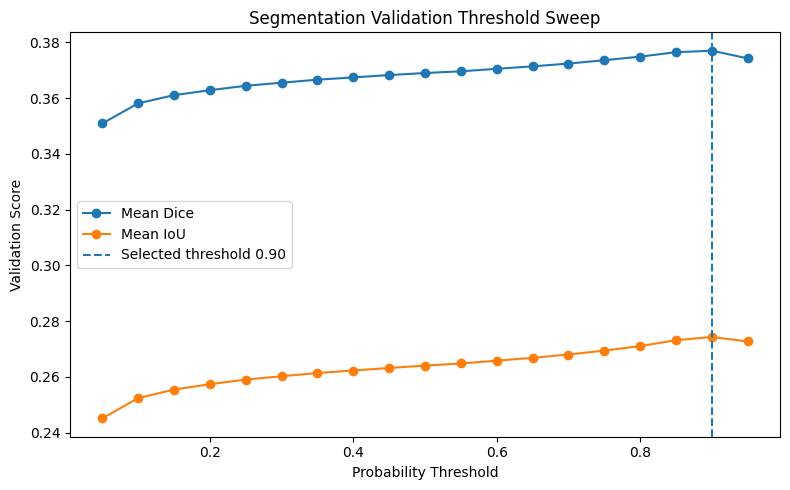

In [18]:
plt.figure(
    figsize=(8, 5)
)

plt.plot(
    threshold_df[
        "threshold"
    ],
    threshold_df[
        "mean_dice"
    ],
    marker="o",
    label="Mean Dice",
)

plt.plot(
    threshold_df[
        "threshold"
    ],
    threshold_df[
        "mean_iou"
    ],
    marker="o",
    label="Mean IoU",
)

plt.axvline(
    SELECTED_THRESHOLD,
    linestyle="--",
    label=(
        "Selected threshold "
        f"{SELECTED_THRESHOLD:.2f}"
    ),
)

plt.xlabel(
    "Probability Threshold"
)

plt.ylabel(
    "Validation Score"
)

plt.title(
    "Segmentation Validation Threshold Sweep"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "validation_threshold_sweep.png",
    dpi=180,
)

plt.show()

In [19]:
# ============================================================
# SAVE FINAL VALIDATION THRESHOLD SELECTION
# ============================================================

threshold_selection = {

    "model":
        "ResNet50UNet",

    "checkpoint":
        CHECKPOINT_PATH.name,

    "checkpoint_stage":
        checkpoint.get(
            "stage"
        ),

    "selected_epoch":
        int(
            checkpoint[
                "epoch"
            ]
        ),

    "selection_dataset":
        "validation",

    "selection_metric":
        "mean per-image Dice",

    "selected_threshold":
        float(
            SELECTED_THRESHOLD
        ),

    "validation_soft_dice":
        float(
            validation_soft_dice
        ),

    "validation_dice_at_selected_threshold":
        float(
            BEST_VALIDATION_DICE
        ),

    "validation_iou_at_selected_threshold":
        float(
            BEST_VALIDATION_IOU
        ),

    "test_set_used":
        False,
}


with open(
    OUTPUT_DIR
    / "threshold_selection.json",
    "w",
) as f:

    json.dump(
        threshold_selection,
        f,
        indent=2,
    )


threshold_df.to_csv(
    OUTPUT_DIR
    / "validation_threshold_sweep.csv",
    index=False,
)


print(
    "MODEL LOCKED:"
)

print(
    CHECKPOINT_PATH.name
)

print(
    "\nTHRESHOLD LOCKED:",
    SELECTED_THRESHOLD
)

print(
    "\nValidation Dice:",
    BEST_VALIDATION_DICE
)

print(
    "Validation IoU:",
    BEST_VALIDATION_IOU
)

print(
    "\nTEST SET UNTOUCHED."
)

MODEL LOCKED:
resnet50_unet_layer4_best.pth

THRESHOLD LOCKED: 0.9000000000000001

Validation Dice: 0.3770005702972412
Validation IoU: 0.2743273079395294

TEST SET UNTOUCHED.


In [20]:
from pathlib import Path
import json
import shutil


# ============================================================
# CREATE VALIDATION-EVALUATION ARTIFACT
# ============================================================

ARTIFACT_DIR = Path(
    "/kaggle/working/segmentation_validation_artifact"
)

ARTIFACT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


FIGURE_ARTIFACT_DIR = (
    ARTIFACT_DIR / "figures"
)

FIGURE_ARTIFACT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# COPY THRESHOLD SELECTION
# ============================================================

threshold_file = (
    OUTPUT_DIR / "threshold_selection.json"
)

assert threshold_file.exists()

shutil.copy2(
    threshold_file,
    ARTIFACT_DIR / "threshold_selection.json",
)


# ============================================================
# COPY THRESHOLD SWEEP CSV
# ============================================================

sweep_file = (
    OUTPUT_DIR / "validation_threshold_sweep.csv"
)

assert sweep_file.exists()

shutil.copy2(
    sweep_file,
    ARTIFACT_DIR / "validation_threshold_sweep.csv",
)


# ============================================================
# COPY VALIDATION FIGURE
# ============================================================

figure_file = (
    FIGURE_DIR / "validation_threshold_sweep.png"
)

if figure_file.exists():

    shutil.copy2(
        figure_file,
        FIGURE_ARTIFACT_DIR
        / "validation_threshold_sweep.png",
    )


# ============================================================
# SAVE BASELINE SUMMARY
# ============================================================

baseline_summary = {
    "model": "Vanilla U-Net",
    "checkpoint": "unet_best.pth",
    "selected_epoch": int(
        checkpoint["epoch"]
    ),

    "validation_soft_dice": float(
        validation_soft_dice
    ),

    "selected_threshold": float(
        SELECTED_THRESHOLD
    ),

    "validation_dice_at_selected_threshold": float(
        BEST_VALIDATION_DICE
    ),

    "validation_iou_at_selected_threshold": float(
        BEST_VALIDATION_IOU
    ),

    "threshold_selection_dataset": "validation",

    "test_set_used": False,

    "status": (
        "Baseline preserved. "
        "Test evaluation deferred while "
        "improved segmentation model is explored."
    ),
}


with open(
    ARTIFACT_DIR / "baseline_summary.json",
    "w",
) as f:

    json.dump(
        baseline_summary,
        f,
        indent=2,
    )


# ============================================================
# VERIFY
# ============================================================

print("Segmentation validation artifact:")
print("-" * 60)

for path in sorted(
    ARTIFACT_DIR.rglob("*")
):

    if path.is_file():

        print(
            path.relative_to(
                ARTIFACT_DIR
            )
        )


# ============================================================
# ZIP
# ============================================================

zip_path = shutil.make_archive(
    "/kaggle/working/"
    "segmentation_validation_artifact",
    "zip",
    ARTIFACT_DIR,
)


print("\nZIP created:")
print(zip_path)

Segmentation validation artifact:
------------------------------------------------------------
baseline_summary.json
figures/validation_threshold_sweep.png
threshold_selection.json
validation_threshold_sweep.csv

ZIP created:
/kaggle/working/segmentation_validation_artifact.zip


In [21]:
from pathlib import Path
import json
import shutil


# ============================================================
# CREATE FINAL VALIDATION ARTIFACT
# ============================================================

ARTIFACT_DIR = Path(
    "/kaggle/working/"
    "resnet50_unet_validation_artifact"
)

if ARTIFACT_DIR.exists():
    shutil.rmtree(
        ARTIFACT_DIR
    )

ARTIFACT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


FIGURE_ARTIFACT_DIR = (
    ARTIFACT_DIR / "figures"
)

FIGURE_ARTIFACT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# COPY THRESHOLD FILES
# ============================================================

shutil.copy2(
    OUTPUT_DIR
    / "threshold_selection.json",
    ARTIFACT_DIR
    / "threshold_selection.json",
)


shutil.copy2(
    OUTPUT_DIR
    / "validation_threshold_sweep.csv",
    ARTIFACT_DIR
    / "validation_threshold_sweep.csv",
)


# ============================================================
# COPY THRESHOLD FIGURE
# ============================================================

figure_file = (
    FIGURE_DIR
    / "validation_threshold_sweep.png"
)

if figure_file.exists():

    shutil.copy2(
        figure_file,
        FIGURE_ARTIFACT_DIR
        / "validation_threshold_sweep.png",
    )


# ============================================================
# SAVE VALIDATION SUMMARY
# ============================================================

validation_summary = {

    "model":
        "ResNet50UNet",

    "checkpoint":
        CHECKPOINT_PATH.name,

    "checkpoint_stage":
        checkpoint.get("stage"),

    "selected_epoch":
        int(
            checkpoint["epoch"]
        ),

    "validation_soft_dice":
        float(
            validation_soft_dice
        ),

    "selected_threshold":
        float(
            SELECTED_THRESHOLD
        ),

    "validation_dice_at_selected_threshold":
        float(
            BEST_VALIDATION_DICE
        ),

    "validation_iou_at_selected_threshold":
        float(
            BEST_VALIDATION_IOU
        ),

    "threshold_selection_dataset":
        "validation",

    "threshold_selection_metric":
        "mean per-image Dice",

    "test_set_used":
        False,

    "status":
        (
            "Final segmentation model and "
            "probability threshold locked. "
            "Ready for one-time held-out "
            "test evaluation."
        ),
}


with open(
    ARTIFACT_DIR
    / "validation_summary.json",
    "w",
) as f:

    json.dump(
        validation_summary,
        f,
        indent=2,
    )


# ============================================================
# VERIFY
# ============================================================

print(
    "ResNet50-U-Net validation artifact:"
)

print("-" * 60)

for path in sorted(
    ARTIFACT_DIR.rglob("*")
):

    if path.is_file():

        print(
            path.relative_to(
                ARTIFACT_DIR
            )
        )


# ============================================================
# ZIP
# ============================================================

zip_path = shutil.make_archive(
    "/kaggle/working/"
    "resnet50_unet_validation_artifact",
    "zip",
    ARTIFACT_DIR,
)


print("\nZIP created:")
print(zip_path)

ResNet50-U-Net validation artifact:
------------------------------------------------------------
figures/validation_threshold_sweep.png
threshold_selection.json
validation_summary.json
validation_threshold_sweep.csv

ZIP created:
/kaggle/working/resnet50_unet_validation_artifact.zip


In [22]:
# ============================================================
# VERIFY LOCKED EVALUATION CONFIGURATION
# ============================================================

THRESHOLD_PATH = (
    OUTPUT_DIR
    / "threshold_selection.json"
)

assert THRESHOLD_PATH.exists()

with open(
    THRESHOLD_PATH,
    "r",
) as f:
    locked_selection = json.load(f)


LOCKED_THRESHOLD = float(
    locked_selection[
        "selected_threshold"
    ]
)

assert (
    CHECKPOINT_PATH.name
    ==
    locked_selection[
        "checkpoint"
    ]
)

assert (
    abs(
        LOCKED_THRESHOLD
        - SELECTED_THRESHOLD
    )
    < 1e-8
)


print("FINAL MODEL:")
print(CHECKPOINT_PATH.name)

print("\nFINAL EPOCH:")
print(checkpoint["epoch"])

print("\nLOCKED THRESHOLD:")
print(LOCKED_THRESHOLD)

print("\nReady for held-out test evaluation.")

FINAL MODEL:
resnet50_unet_layer4_best.pth

FINAL EPOCH:
3

LOCKED THRESHOLD:
0.9000000000000001

Ready for held-out test evaluation.


In [23]:
# ============================================================
# LOAD HELD-OUT TEST MANIFEST
# ============================================================

test_df = pd.read_csv(
    SPLITS_DIR / "test.csv"
)

assert len(test_df) == 394

assert (
    test_df["image_key"]
    .is_unique
)

print(
    "Test images:",
    len(test_df)
)

print(
    "\nAbnormality distribution:"
)

notebook_display(
    test_df[
        "abnormality_type"
    ].value_counts(
        dropna=False
    )
)

Test images: 394

Abnormality distribution:


abnormality_type
calcification         216
mass                  170
mass+calcification      8
Name: count, dtype: int64

In [24]:
# ============================================================
# LOAD TEST SET INTO RAM
# ============================================================

test_dataset = (
    load_segmentation_split_into_ram(
        dataframe=test_df,
        root_dir=PROJECT_ROOT,
        split_name="Test",
    )
)


test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)


print(
    "Test samples:",
    len(test_dataset)
)

print(
    "Test batches:",
    len(test_loader)
)

Loading Test into RAM:   0%|          | 0/394 [00:00<?, ?it/s]


Test: 394 samples loaded
Images: torch.Size([394, 1024, 640]) torch.uint16
Masks: torch.Size([394, 1024, 640]) torch.uint8
Test samples: 394
Test batches: 197


In [25]:
# ============================================================
# ONE-TIME HELD-OUT TEST INFERENCE
# ============================================================

TEST_METRICS_PATH = (
    OUTPUT_DIR
    / "test_segmentation_metrics.csv"
)

TEST_INFERENCE_MARKER = (
    OUTPUT_DIR
    / "TEST_INFERENCE_COMPLETED.txt"
)


assert not TEST_INFERENCE_MARKER.exists(), (
    "Test inference has already been completed. "
    "Do not rerun this cell."
)


# Start with a clean prediction directory.
if PREDICTION_DIR.exists():
    shutil.rmtree(
        PREDICTION_DIR
    )

PREDICTION_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


test_records = []


model.eval()


with torch.inference_mode():

    for (
        images,
        masks,
        image_keys,
    ) in tqdm(
        test_loader,
        desc="FINAL test inference",
    ):

        images, masks = (
            prepare_segmentation_batch(
                images,
                masks,
            )
        )


        logits = model(
            images
        )

        probabilities = torch.sigmoid(
            logits
        )


        predictions = (
            probabilities
            >= LOCKED_THRESHOLD
        )


        # ----------------------------------------------------
        # SOFT DICE
        # ----------------------------------------------------

        dimensions = (
            1,
            2,
            3,
        )


        soft_intersection = (
            probabilities
            * masks
        ).sum(
            dim=dimensions
        )


        soft_denominator = (
            probabilities.sum(
                dim=dimensions
            )
            +
            masks.sum(
                dim=dimensions
            )
        )


        soft_dice = (
            2.0
            * soft_intersection
            + 1.0
        ) / (
            soft_denominator
            + 1.0
        )


        # ----------------------------------------------------
        # HARD METRICS
        # ----------------------------------------------------

        targets = (
            masks > 0.5
        )


        intersection = (
            predictions
            & targets
        ).sum(
            dim=dimensions
        ).float()


        predicted_pixels = (
            predictions.sum(
                dim=dimensions
            ).float()
        )


        target_pixels = (
            targets.sum(
                dim=dimensions
            ).float()
        )


        union = (
            predicted_pixels
            + target_pixels
            - intersection
        )


        dice = (
            2.0 * intersection
            + 1.0
        ) / (
            predicted_pixels
            + target_pixels
            + 1.0
        )


        iou = (
            intersection
            + 1.0
        ) / (
            union
            + 1.0
        )


        precision = (
            intersection
            /
            (
                predicted_pixels
                + 1e-8
            )
        )


        recall = (
            intersection
            /
            (
                target_pixels
                + 1e-8
            )
        )


        # ----------------------------------------------------
        # SAVE EACH SAMPLE
        # ----------------------------------------------------

        batch_size = (
            images.shape[0]
        )


        for j in range(
            batch_size
        ):

            image_key = (
                image_keys[j]
            )

            safe_key = (
                str(image_key)
                .replace("/", "_")
                .replace("\\", "_")
            )


            prediction_filename = (
                f"{safe_key}.png"
            )


            prediction_path = (
                PREDICTION_DIR
                / prediction_filename
            )


            prediction_array = (
                predictions[
                    j,
                    0,
                ]
                .detach()
                .cpu()
                .numpy()
                .astype(
                    np.uint8
                )
                * 255
            )


            cv2.imwrite(
                str(
                    prediction_path
                ),
                prediction_array,
            )


            test_records.append(
                {
                    "image_key":
                        image_key,

                    "soft_dice":
                        float(
                            soft_dice[j]
                            .item()
                        ),

                    "dice":
                        float(
                            dice[j]
                            .item()
                        ),

                    "iou":
                        float(
                            iou[j]
                            .item()
                        ),

                    "precision":
                        float(
                            precision[j]
                            .item()
                        ),

                    "recall":
                        float(
                            recall[j]
                            .item()
                        ),

                    "intersection_pixels":
                        int(
                            intersection[j]
                            .item()
                        ),

                    "predicted_pixels":
                        int(
                            predicted_pixels[j]
                            .item()
                        ),

                    "target_pixels":
                        int(
                            target_pixels[j]
                            .item()
                        ),

                    "prediction_path":
                        str(
                            prediction_path
                        ),
                }
            )


# ============================================================
# SAVE RESULTS
# ============================================================

test_metrics_df = pd.DataFrame(
    test_records
)


assert (
    len(test_metrics_df)
    ==
    len(test_df)
)


test_metrics_df.to_csv(
    TEST_METRICS_PATH,
    index=False,
)


with open(
    TEST_INFERENCE_MARKER,
    "w",
) as f:

    f.write(
        "Held-out test inference completed "
        "using locked model and threshold.\n"
    )

    f.write(
        f"Checkpoint: "
        f"{CHECKPOINT_PATH.name}\n"
    )

    f.write(
        f"Epoch: "
        f"{checkpoint['epoch']}\n"
    )

    f.write(
        f"Threshold: "
        f"{LOCKED_THRESHOLD}\n"
    )


print(
    "\nFINAL TEST INFERENCE COMPLETE."
)

print(
    "Do not rerun this cell."
)

print(
    "\nSaved:",
    TEST_METRICS_PATH
)

FINAL test inference:   0%|          | 0/197 [00:00<?, ?it/s]


FINAL TEST INFERENCE COMPLETE.
Do not rerun this cell.

Saved: /kaggle/working/segmentation_evaluation/test_segmentation_metrics.csv


In [26]:
# ============================================================
# FINAL TEST METRICS
# ============================================================

test_summary = {

    "n_images":
        int(
            len(
                test_metrics_df
            )
        ),

    "mean_soft_dice":
        float(
            test_metrics_df[
                "soft_dice"
            ].mean()
        ),

    "mean_dice":
        float(
            test_metrics_df[
                "dice"
            ].mean()
        ),

    "median_dice":
        float(
            test_metrics_df[
                "dice"
            ].median()
        ),

    "mean_iou":
        float(
            test_metrics_df[
                "iou"
            ].mean()
        ),

    "median_iou":
        float(
            test_metrics_df[
                "iou"
            ].median()
        ),

    "mean_precision":
        float(
            test_metrics_df[
                "precision"
            ].mean()
        ),

    "mean_recall":
        float(
            test_metrics_df[
                "recall"
            ].mean()
        ),
}


print(
    "FINAL HELD-OUT TEST RESULTS"
)

print("=" * 50)


for key, value in (
    test_summary.items()
):

    if key == "n_images":

        print(
            f"{key:20s}: "
            f"{value}"
        )

    else:

        print(
            f"{key:20s}: "
            f"{value:.4f}"
        )

FINAL HELD-OUT TEST RESULTS
n_images            : 394
mean_soft_dice      : 0.3493
mean_dice           : 0.3695
median_dice         : 0.3663
mean_iou            : 0.2699
median_iou          : 0.2242
mean_precision      : 0.4329
mean_recall         : 0.4414


In [27]:
# ============================================================
# ATTACH TEST METADATA
# ============================================================

metadata_columns = [
    "image_key",
    "patient_id",
    "abnormality_type",
    "malignant",
    "lesion_count",
]


metadata_columns = [
    column
    for column in metadata_columns
    if column
    in test_df.columns
]


test_analysis_df = (
    test_metrics_df.merge(
        test_df[
            metadata_columns
        ],
        on="image_key",
        how="left",
        validate="one_to_one",
    )
)


assert (
    test_analysis_df[
        "patient_id"
    ].notna().all()
)


test_analysis_df[
    "lesion_fraction"
] = (
    test_analysis_df[
        "target_pixels"
    ]
    /
    (
        TARGET_HEIGHT
        * TARGET_WIDTH
    )
)


test_analysis_df.to_csv(
    OUTPUT_DIR
    / "test_segmentation_analysis.csv",
    index=False,
)


notebook_display(
    test_analysis_df.head()
)

,image_key,soft_dice,dice,iou,precision,recall,intersection_pixels,predicted_pixels,target_pixels,prediction_path,patient_id,abnormality_type,malignant,lesion_count,lesion_fraction
0,P_00014_LEFT_CC,0.225520,0.315291,0.187174,0.187124,1.000000,3081,16465,3081,/kaggle/working/segmentation_evaluation/predic...,P_00014,calcification,1,1,0.004701
1,P_00014_LEFT_MLO,0.389177,0.447593,0.288379,0.289836,0.981542,1808,6238,1842,/kaggle/working/segmentation_evaluation/predic...,P_00014,calcification,1,1,0.002811
2,P_00019_RIGHT_CC,0.809454,0.816452,0.689855,0.892735,0.752155,5235,5864,6960,/kaggle/working/segmentation_evaluation/predic...,P_00019,calcification,0,1,0.010620
3,P_00019_RIGHT_MLO,0.000397,0.000090,0.000090,0.000000,0.000000,0,1503,9652,/kaggle/working/segmentation_evaluation/predic...,P_00019,calcification,0,1,0.014728
4,P_00023_RIGHT_CC,0.771019,0.871538,0.772404,0.818250,0.932131,1085,1326,1164,/kaggle/working/segmentation_evaluation/predic...,P_00023,mass,1,1,0.001776


In [28]:
# ============================================================
# ABNORMALITY-TYPE PERFORMANCE
# ============================================================

abnormality_metrics = (
    test_analysis_df.groupby(
        "abnormality_type",
        dropna=False,
    )
    .agg(
        n=(
            "image_key",
            "size",
        ),

        mean_dice=(
            "dice",
            "mean",
        ),

        median_dice=(
            "dice",
            "median",
        ),

        mean_iou=(
            "iou",
            "mean",
        ),

        median_iou=(
            "iou",
            "median",
        ),

        mean_precision=(
            "precision",
            "mean",
        ),

        mean_recall=(
            "recall",
            "mean",
        ),

        mean_lesion_fraction=(
            "lesion_fraction",
            "mean",
        ),
    )
    .reset_index()
)


abnormality_metrics.to_csv(
    OUTPUT_DIR
    / "test_metrics_by_abnormality_type.csv",
    index=False,
)


notebook_display(
    abnormality_metrics
)

,abnormality_type,n,mean_dice,median_dice,mean_iou,median_iou,mean_precision,mean_recall,mean_lesion_fraction
0,calcification,216,0.318750,0.269019,0.225596,0.155492,0.418888,0.404254,0.023731
1,mass,170,0.429290,0.501792,0.323074,0.334974,0.445850,0.486350,0.006031
2,mass+calcification,8,0.467402,0.512554,0.335970,0.344636,0.537890,0.487632,0.017575


In [29]:
# ============================================================
# LESION-SIZE ANALYSIS
# ============================================================

size_labels = [
    "Q1 smallest",
    "Q2",
    "Q3",
    "Q4 largest",
]


# Ranking first guarantees four bins even
# when multiple lesions have identical areas.
size_rank = (
    test_analysis_df[
        "target_pixels"
    ].rank(
        method="first"
    )
)


test_analysis_df[
    "lesion_size_bin"
] = pd.qcut(
    size_rank,
    q=4,
    labels=size_labels,
)


size_metrics = (
    test_analysis_df.groupby(
        "lesion_size_bin",
        observed=True,
    )
    .agg(
        n=(
            "image_key",
            "size",
        ),

        mean_target_pixels=(
            "target_pixels",
            "mean",
        ),

        mean_dice=(
            "dice",
            "mean",
        ),

        median_dice=(
            "dice",
            "median",
        ),

        mean_iou=(
            "iou",
            "mean",
        ),

        mean_recall=(
            "recall",
            "mean",
        ),
    )
    .reset_index()
)


size_metrics.to_csv(
    OUTPUT_DIR
    / "test_metrics_by_lesion_size.csv",
    index=False,
)


notebook_display(
    size_metrics
)

,lesion_size_bin,n,mean_target_pixels,mean_dice,median_dice,mean_iou,mean_recall
0,Q1 smallest,99,941.111111,0.310011,0.292313,0.221495,0.551137
1,Q2,98,2456.673469,0.340915,0.326784,0.250516,0.433494
2,Q3,98,5451.826531,0.437167,0.510584,0.322457,0.438580
3,Q4 largest,99,32880.282828,0.390155,0.362398,0.285451,0.342158


In [30]:
# ============================================================
# PATIENT-CLUSTER BOOTSTRAP
# ============================================================

BOOTSTRAP_SAMPLES = 2000

rng = np.random.default_rng(
    SEED
)


patient_groups = {
    patient_id:
        group.index.to_numpy()

    for (
        patient_id,
        group,
    ) in test_analysis_df.groupby(
        "patient_id"
    )
}


patient_ids = np.array(
    list(
        patient_groups.keys()
    )
)


bootstrap_records = []


for bootstrap_index in tqdm(
    range(
        BOOTSTRAP_SAMPLES
    ),
    desc="Patient bootstrap",
):

    sampled_patients = (
        rng.choice(
            patient_ids,
            size=len(
                patient_ids
            ),
            replace=True,
        )
    )


    sampled_indices = (
        np.concatenate(
            [
                patient_groups[
                    patient
                ]

                for patient
                in sampled_patients
            ]
        )
    )


    sample = (
        test_analysis_df.loc[
            sampled_indices
        ]
    )


    bootstrap_records.append(
        {
            "bootstrap":
                bootstrap_index,

            "mean_dice":
                sample[
                    "dice"
                ].mean(),

            "mean_iou":
                sample[
                    "iou"
                ].mean(),

            "mean_precision":
                sample[
                    "precision"
                ].mean(),

            "mean_recall":
                sample[
                    "recall"
                ].mean(),
        }
    )


bootstrap_df = pd.DataFrame(
    bootstrap_records
)


bootstrap_df.to_csv(
    OUTPUT_DIR
    / "patient_bootstrap_segmentation.csv",
    index=False,
)


confidence_intervals = {}


for metric in [
    "mean_dice",
    "mean_iou",
    "mean_precision",
    "mean_recall",
]:

    confidence_intervals[
        metric
    ] = {

        "lower_95":
            float(
                bootstrap_df[
                    metric
                ].quantile(
                    0.025
                )
            ),

        "upper_95":
            float(
                bootstrap_df[
                    metric
                ].quantile(
                    0.975
                )
            ),
    }


print(
    json.dumps(
        confidence_intervals,
        indent=2,
    )
)


with open(
    OUTPUT_DIR
    / "confidence_intervals.json",
    "w",
) as f:

    json.dump(
        confidence_intervals,
        f,
        indent=2,
    )

Patient bootstrap:   0%|          | 0/2000 [00:00<?, ?it/s]

{
  "mean_dice": {
    "lower_95": 0.33624484025342355,
    "upper_95": 0.4038961316042253
  },
  "mean_iou": {
    "lower_95": 0.2435915802446914,
    "upper_95": 0.29785688191072685
  },
  "mean_precision": {
    "lower_95": 0.39311609720796237,
    "upper_95": 0.47512993786005114
  },
  "mean_recall": {
    "lower_95": 0.3991867558793141,
    "upper_95": 0.48350716911312647
  }
}


In [31]:
# ============================================================
# SELECT QUALITATIVE EXAMPLES
# ============================================================

sorted_results = (
    test_analysis_df.sort_values(
        "dice",
        ascending=False,
    )
    .reset_index(
        drop=True
    )
)


best_cases = (
    sorted_results.head(
        3
    )
)


worst_cases = (
    sorted_results.tail(
        3
    )
    .sort_values(
        "dice"
    )
)


median_dice = (
    test_analysis_df[
        "dice"
    ].median()
)


typical_cases = (
    test_analysis_df.assign(
        distance_from_median=
        (
            test_analysis_df[
                "dice"
            ]
            - median_dice
        ).abs()
    )
    .sort_values(
        "distance_from_median"
    )
    .head(
        3
    )
)


print("BEST CASES")
notebook_display(
    best_cases[
        [
            "image_key",
            "abnormality_type",
            "dice",
            "iou",
        ]
    ]
)


print("\nTYPICAL CASES")
notebook_display(
    typical_cases[
        [
            "image_key",
            "abnormality_type",
            "dice",
            "iou",
        ]
    ]
)


print("\nWORST CASES")
notebook_display(
    worst_cases[
        [
            "image_key",
            "abnormality_type",
            "dice",
            "iou",
        ]
    ]
)

BEST CASES


,image_key,abnormality_type,dice,iou
0,P_01136_RIGHT_CC,calcification,0.899467,0.817304
1,P_00023_RIGHT_CC,mass,0.871538,0.772404
2,P_01326_LEFT_CC,mass,0.870720,0.771051



TYPICAL CASES


,image_key,abnormality_type,dice,iou
142,P_00712_RIGHT_CC,calcification,0.367649,0.225229
218,P_01142_RIGHT_CC,mass,0.364866,0.223197
284,P_01383_LEFT_CC,mass,0.364779,0.223124



WORST CASES


,image_key,abnormality_type,dice,iou
393,P_02418_RIGHT_CC,calcification,0.000011,0.000011
392,P_00624_LEFT_CC,calcification,0.000019,0.000019
391,P_00812_LEFT_MLO,calcification,0.000025,0.000025


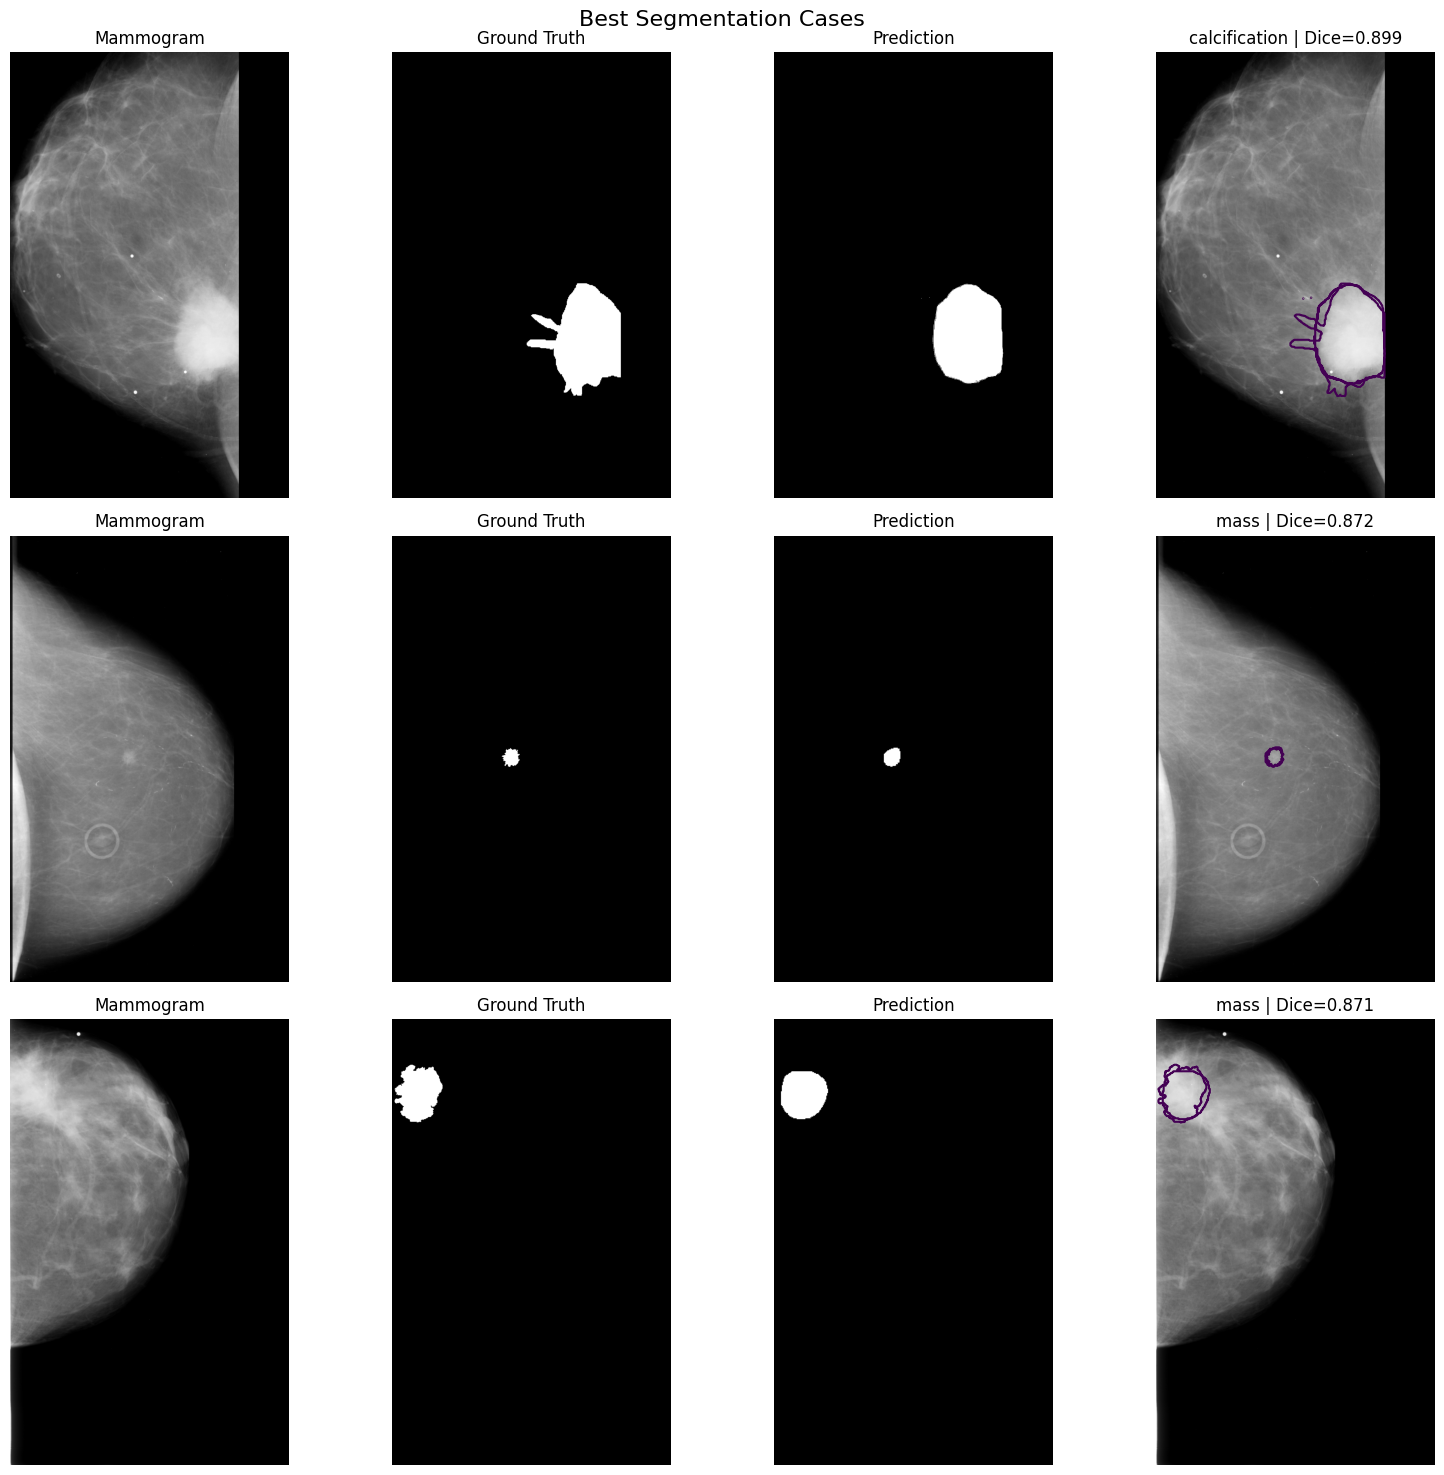

Saved: /kaggle/working/segmentation_evaluation/figures/test_best_cases.png


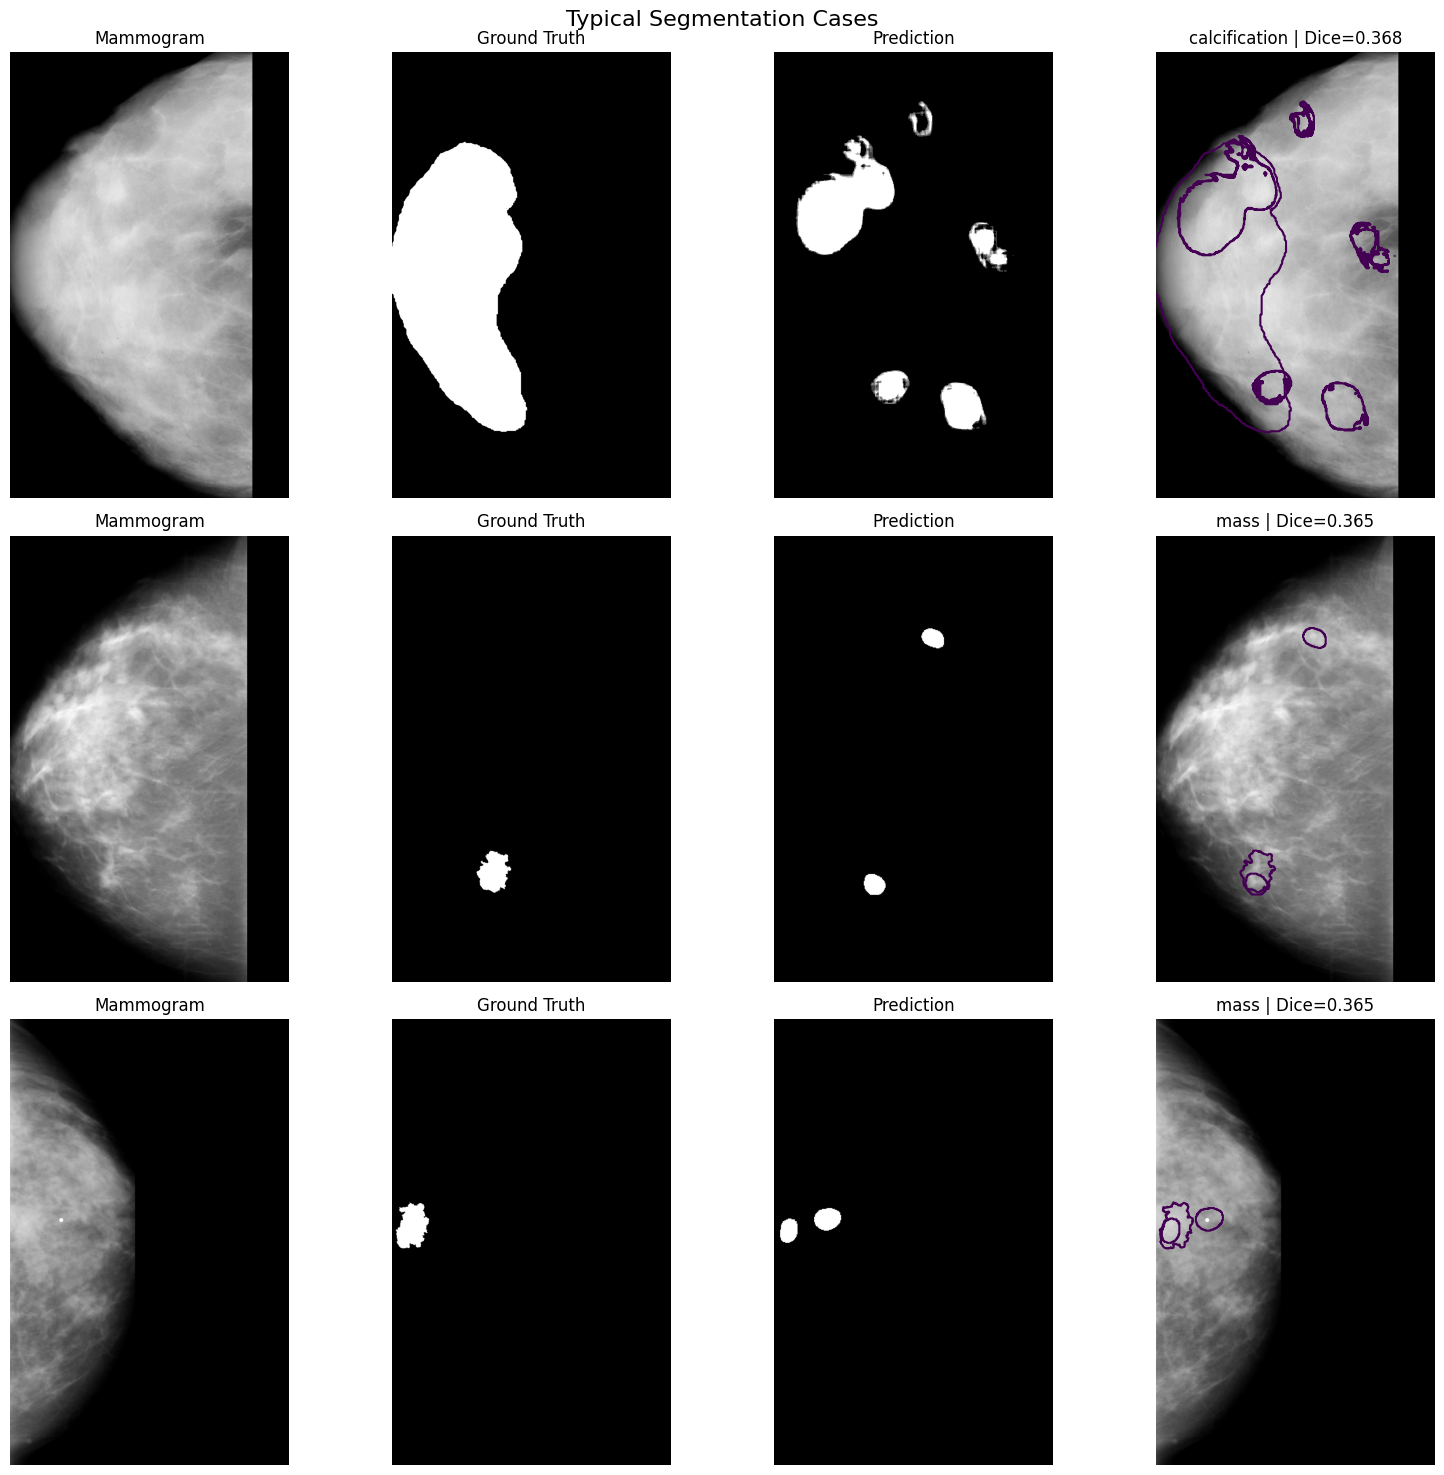

Saved: /kaggle/working/segmentation_evaluation/figures/test_typical_cases.png


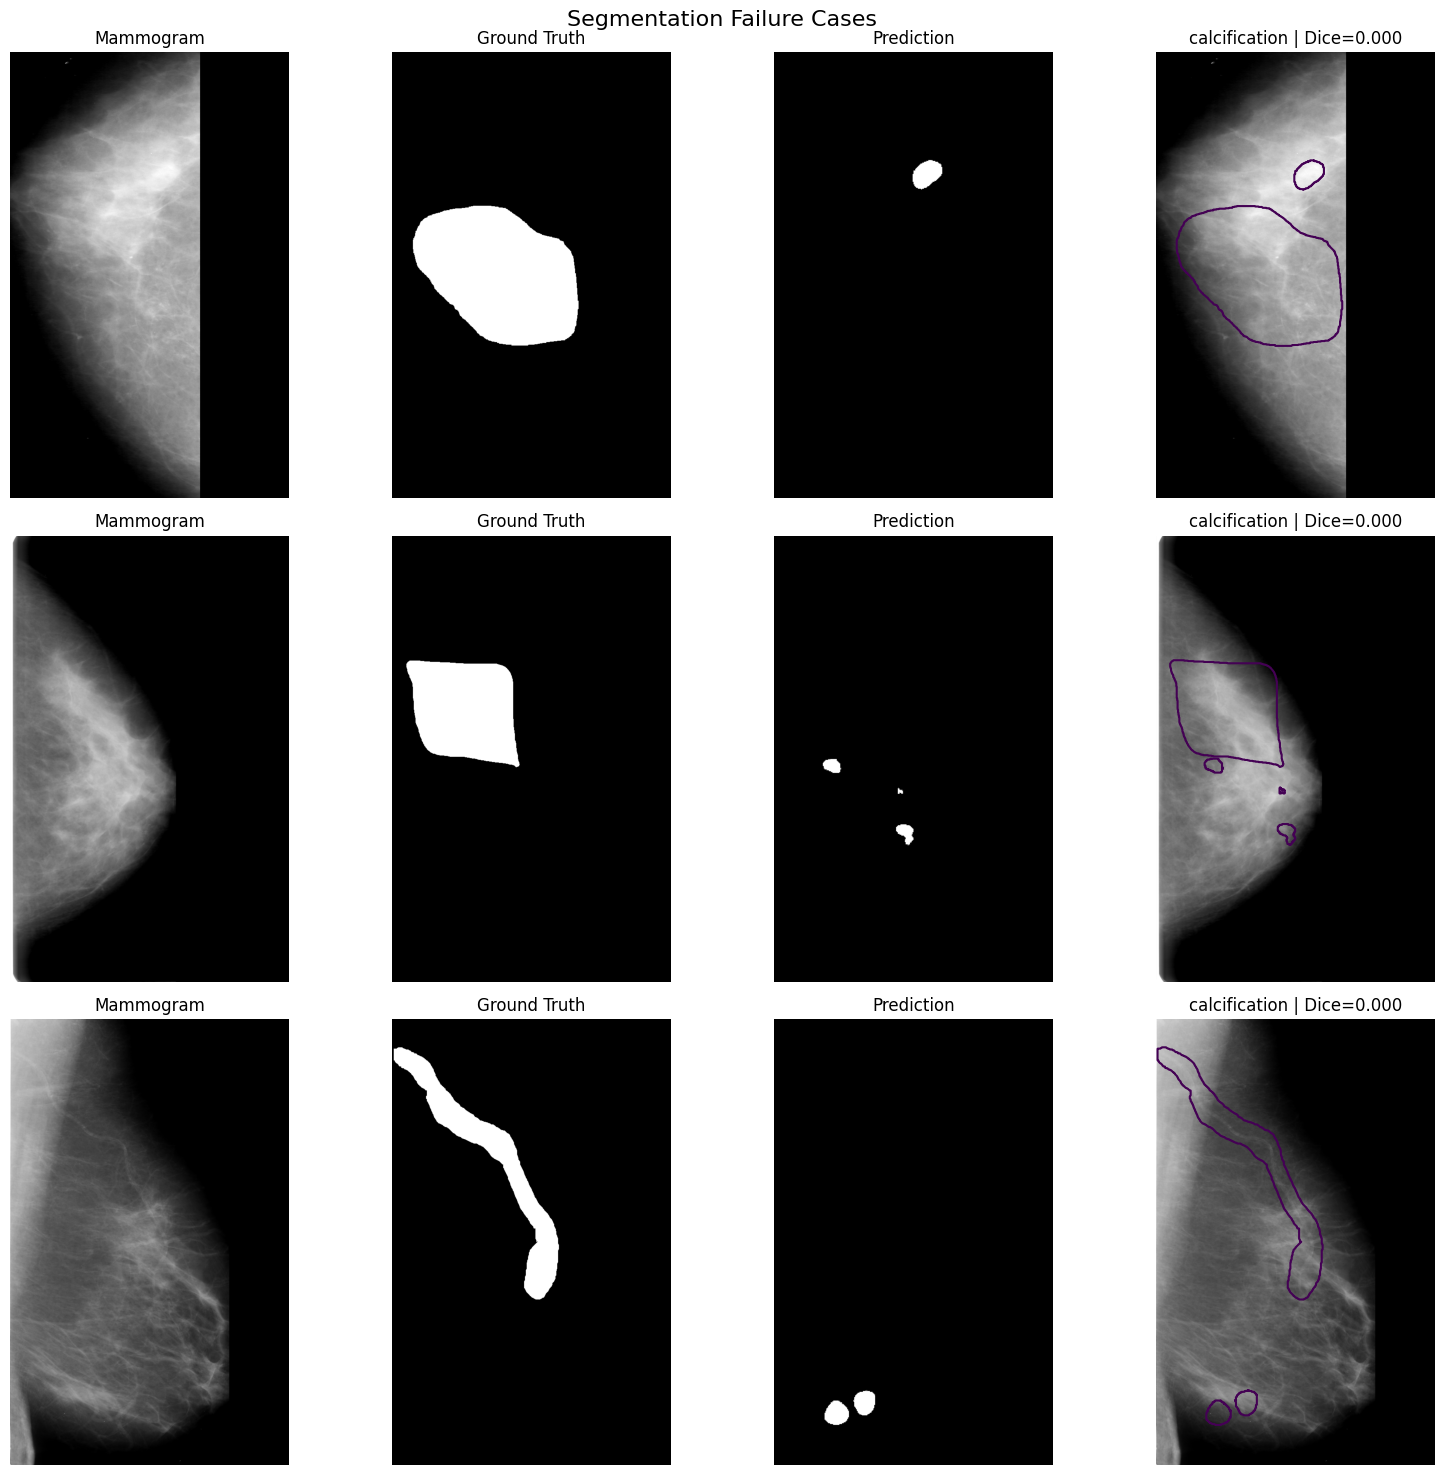

Saved: /kaggle/working/segmentation_evaluation/figures/test_worst_cases.png


In [32]:
# ============================================================
# QUALITATIVE VISUALIZATION
# ============================================================

test_key_to_index = {
    key: index

    for index, key
    in enumerate(
        test_dataset.image_keys
    )
}


def save_case_figure(
    cases,
    filename,
    title,
):

    n = len(cases)

    fig, axes = plt.subplots(
        nrows=n,
        ncols=4,
        figsize=(
            16,
            5 * n,
        ),
    )


    if n == 1:
        axes = np.expand_dims(
            axes,
            axis=0,
        )


    for row_index, (
        _,
        case,
    ) in enumerate(
        cases.iterrows()
    ):

        image_key = (
            case[
                "image_key"
            ]
        )

        dataset_index = (
            test_key_to_index[
                image_key
            ]
        )


        image = (
            test_dataset.images[
                dataset_index
            ]
            .numpy()
        )


        ground_truth = (
            test_dataset.masks[
                dataset_index
            ]
            .numpy()
        )


        prediction = cv2.imread(
            case[
                "prediction_path"
            ],
            cv2.IMREAD_GRAYSCALE,
        )


        prediction = (
            prediction > 0
        )


        # --------------------------------------------
        # Mammogram
        # --------------------------------------------

        axes[
            row_index,
            0,
        ].imshow(
            image,
            cmap="gray",
        )

        axes[
            row_index,
            0,
        ].set_title(
            "Mammogram"
        )


        # --------------------------------------------
        # Ground truth
        # --------------------------------------------

        axes[
            row_index,
            1,
        ].imshow(
            ground_truth,
            cmap="gray",
        )

        axes[
            row_index,
            1,
        ].set_title(
            "Ground Truth"
        )


        # --------------------------------------------
        # Prediction
        # --------------------------------------------

        axes[
            row_index,
            2,
        ].imshow(
            prediction,
            cmap="gray",
        )

        axes[
            row_index,
            2,
        ].set_title(
            "Prediction"
        )


        # --------------------------------------------
        # Overlay
        # --------------------------------------------

        axes[
            row_index,
            3,
        ].imshow(
            image,
            cmap="gray",
        )

        axes[
            row_index,
            3,
        ].contour(
            ground_truth,
            levels=[0.5],
            linewidths=1.5,
        )

        axes[
            row_index,
            3,
        ].contour(
            prediction,
            levels=[0.5],
            linewidths=1.5,
        )


        axes[
            row_index,
            3,
        ].set_title(
            (
                f"{case['abnormality_type']} | "
                f"Dice={case['dice']:.3f}"
            )
        )


        for column in range(
            4
        ):

            axes[
                row_index,
                column,
            ].axis(
                "off"
            )


    fig.suptitle(
        title,
        fontsize=16,
    )

    plt.tight_layout()

    save_path = (
        FIGURE_DIR
        / filename
    )

    plt.savefig(
        save_path,
        dpi=160,
        bbox_inches="tight",
    )

    plt.show()

    print(
        "Saved:",
        save_path
    )


save_case_figure(
    best_cases,
    "test_best_cases.png",
    "Best Segmentation Cases",
)


save_case_figure(
    typical_cases,
    "test_typical_cases.png",
    "Typical Segmentation Cases",
)


save_case_figure(
    worst_cases,
    "test_worst_cases.png",
    "Segmentation Failure Cases",
)

In [33]:
# ============================================================
# FINAL SEGMENTATION SUMMARY
# ============================================================

final_evaluation_summary = {

    "model":
        "ResNet50UNet",

    "checkpoint":
        CHECKPOINT_PATH.name,

    "selected_epoch":
        int(
            checkpoint[
                "epoch"
            ]
        ),

    "threshold":
        float(
            LOCKED_THRESHOLD
        ),

    "threshold_selected_using":
        "validation set only",

    "test_images":
        int(
            len(
                test_metrics_df
            )
        ),

    "test_metrics":
        test_summary,

    "patient_bootstrap_95_ci":
        confidence_intervals,

    "test_inference_runs":
        1,

    "notes":
        (
            "Model architecture, checkpoint, "
            "and probability threshold were "
            "locked before opening the held-out "
            "test split. No test-set information "
            "was used for model or threshold "
            "selection."
        ),
}


with open(
    OUTPUT_DIR
    / "final_segmentation_evaluation.json",
    "w",
) as f:

    json.dump(
        final_evaluation_summary,
        f,
        indent=2,
    )


print(
    json.dumps(
        final_evaluation_summary,
        indent=2,
    )
)

{
  "model": "ResNet50UNet",
  "checkpoint": "resnet50_unet_layer4_best.pth",
  "selected_epoch": 3,
  "threshold": 0.9000000000000001,
  "threshold_selected_using": "validation set only",
  "test_images": 394,
  "test_metrics": {
    "n_images": 394,
    "mean_soft_dice": 0.349320959276239,
    "mean_dice": 0.3694631594787148,
    "median_dice": 0.3662576228380203,
    "mean_iou": 0.2698958679667079,
    "median_iou": 0.22421281784772873,
    "mean_precision": 0.4329377337661601,
    "mean_recall": 0.44136928919945645
  },
  "patient_bootstrap_95_ci": {
    "mean_dice": {
      "lower_95": 0.33624484025342355,
      "upper_95": 0.4038961316042253
    },
    "mean_iou": {
      "lower_95": 0.2435915802446914,
      "upper_95": 0.29785688191072685
    },
    "mean_precision": {
      "lower_95": 0.39311609720796237,
      "upper_95": 0.47512993786005114
    },
    "mean_recall": {
      "lower_95": 0.3991867558793141,
      "upper_95": 0.48350716911312647
    }
  },
  "test_inference_ru

In [34]:
from pathlib import Path
import json
import shutil


# ============================================================
# FINAL SEGMENTATION EVALUATION ARTIFACT
# ============================================================

FINAL_ARTIFACT_DIR = Path(
    "/kaggle/working/final_segmentation_evaluation_artifact"
)

if FINAL_ARTIFACT_DIR.exists():
    shutil.rmtree(
        FINAL_ARTIFACT_DIR
    )

FINAL_ARTIFACT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


FIGURE_ARTIFACT_DIR = (
    FINAL_ARTIFACT_DIR
    / "figures"
)

FIGURE_ARTIFACT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# FILES TO PRESERVE
# ============================================================

files_to_copy = [

    "final_segmentation_evaluation.json",

    "test_segmentation_metrics.csv",

    "test_segmentation_analysis.csv",

    "test_metrics_by_abnormality_type.csv",

    "test_metrics_by_lesion_size.csv",

    "patient_bootstrap_segmentation.csv",

    "confidence_intervals.json",

    "threshold_selection.json",

    "validation_threshold_sweep.csv",

    "TEST_INFERENCE_COMPLETED.txt",
]


for filename in files_to_copy:

    source = (
        OUTPUT_DIR
        / filename
    )

    if source.exists():

        shutil.copy2(
            source,
            FINAL_ARTIFACT_DIR
            / filename,
        )

    else:

        print(
            f"Warning: missing "
            f"{filename}"
        )


# ============================================================
# COPY IMPORTANT FIGURES
# ============================================================

figure_files = [

    "validation_threshold_sweep.png",

    "test_best_cases.png",

    "test_typical_cases.png",

    "test_worst_cases.png",
]


for filename in figure_files:

    source = (
        FIGURE_DIR
        / filename
    )

    if source.exists():

        shutil.copy2(
            source,
            FIGURE_ARTIFACT_DIR
            / filename,
        )

    else:

        print(
            f"Warning: missing figure "
            f"{filename}"
        )


# ============================================================
# SAVE COMPACT FINAL SUMMARY
# ============================================================

artifact_summary = {

    "project_component":
        "lesion_segmentation",

    "model":
        "ResNet50UNet",

    "checkpoint":
        CHECKPOINT_PATH.name,

    "selected_epoch":
        int(
            checkpoint["epoch"]
        ),

    "threshold":
        float(
            LOCKED_THRESHOLD
        ),

    "threshold_selected_on":
        "validation",

    "test_images":
        int(
            len(
                test_metrics_df
            )
        ),

    "final_test_metrics":
        test_summary,

    "patient_bootstrap_95_ci":
        confidence_intervals,

    "test_inference_runs":
        1,

    "important_results": {

        "mean_dice":
            float(
                test_summary[
                    "mean_dice"
                ]
            ),

        "median_dice":
            float(
                test_summary[
                    "median_dice"
                ]
            ),

        "mean_iou":
            float(
                test_summary[
                    "mean_iou"
                ]
            ),

        "mean_precision":
            float(
                test_summary[
                    "mean_precision"
                ]
            ),

        "mean_recall":
            float(
                test_summary[
                    "mean_recall"
                ]
            ),
    },

    "notes":
        (
            "Final segmentation model, epoch, "
            "and probability threshold were "
            "locked before held-out test inference. "
            "Test inference was performed once. "
            "Subgroup, lesion-size, bootstrap, "
            "and qualitative analyses were generated "
            "from saved test outputs."
        ),
}


with open(
    FINAL_ARTIFACT_DIR
    / "artifact_summary.json",
    "w",
) as f:

    json.dump(
        artifact_summary,
        f,
        indent=2,
    )


# ============================================================
# VERIFY CONTENTS
# ============================================================

print(
    "Final segmentation artifact contents:"
)

print("=" * 60)


for path in sorted(
    FINAL_ARTIFACT_DIR.rglob("*")
):

    if path.is_file():

        size_mb = (
            path.stat().st_size
            / (1024 ** 2)
        )

        print(
            f"{path.relative_to(FINAL_ARTIFACT_DIR)}"
            f"  ({size_mb:.2f} MB)"
        )


# ============================================================
# CREATE ZIP
# ============================================================

ZIP_BASE = (
    "/kaggle/working/"
    "final_segmentation_evaluation_artifact"
)

zip_path = shutil.make_archive(
    ZIP_BASE,
    "zip",
    FINAL_ARTIFACT_DIR,
)


zip_size_mb = (
    Path(
        zip_path
    ).stat().st_size
    / (1024 ** 2)
)


print(
    "\nZIP created:"
)

print(
    zip_path
)

print(
    f"ZIP size: "
    f"{zip_size_mb:.2f} MB"
)

Final segmentation artifact contents:
TEST_INFERENCE_COMPLETED.txt  (0.00 MB)
artifact_summary.json  (0.00 MB)
confidence_intervals.json  (0.00 MB)
figures/test_best_cases.png  (0.51 MB)
figures/test_typical_cases.png  (0.58 MB)
figures/test_worst_cases.png  (0.52 MB)
figures/validation_threshold_sweep.png  (0.07 MB)
final_segmentation_evaluation.json  (0.00 MB)
patient_bootstrap_segmentation.csv  (0.16 MB)
test_metrics_by_abnormality_type.csv  (0.00 MB)
test_metrics_by_lesion_size.csv  (0.00 MB)
test_segmentation_analysis.csv  (0.09 MB)
test_segmentation_metrics.csv  (0.07 MB)
threshold_selection.json  (0.00 MB)
validation_threshold_sweep.csv  (0.00 MB)

ZIP created:
/kaggle/working/final_segmentation_evaluation_artifact.zip
ZIP size: 1.68 MB
